# Linear buckling analysis of a plate

A simply supported plate under uniaxial compression, with `Quad4R` elements.
The geometric stiffness matrix comes from the linear static solution of the
reference load, through `update_probe_ue` and `update_KG`, and the eigenvalue
problem is solved with `linear_buckling`, see
[Linear buckling and natural frequencies](../eigenvalue_analyses.rst). The
critical load is compared with the exact buckling load of the simply
supported plate of Leissa (1969), within the discretisation error stated in
the docstring (`tests/test_quad4r_linear_buckling_plate.py`). The element is
described in [Quad4R: one-point integration and hourglass control](../shell_quad4r.rst);
the full references are at the end of the notebook.

In [1]:
import os
import sys

sys.path.insert(0, os.path.join('..', 'tests'))

import numpy as np
import pytest
from numpy import isclose
from scipy.sparse import coo_matrix, diags as sp_diags
from scipy.sparse.linalg import cg, eigsh
from pyfe3d import (DOF, DOUBLE, INT, Quad4R, Quad4RData, Quad4RProbe, Quad4,
                    Quad4Data, Quad4Probe)
from pyfe3d.shellprop_utils import isotropic_plate
from pyfe3d.solver import linear_buckling, diagonal_preconditioner
from test_solver import (A_PLATE, B_PLATE, E_PLATE, H_PLATE, NU_PLATE, NX, NY,
                         RHO_PLATE)

## What the test verifies, and against what

The plate has $a = 2$ m along $x$, $b = 0.5$ m, $h = 0.003$ m, $E = 203$ GPa
and $\nu = 0.33$, and is loaded by uniform compressive forces of 1000 N in
total on the edges $x = 0$ and $x = a$, which balance each other; $w = 0$ on
the four edges, and the in-plane rigid-body modes are removed by holding $u$
at the middle of the edges $y = 0, b$ and $v$ at the middle of the edges
$x = 0, a$. The linear static solution $\boldsymbol{u}_0$ of
that load gives the membrane stresses of each element, hence $\boldsymbol{K}_G$,
and `linear_buckling` solves $(\boldsymbol{K}_{C0} + \lambda \boldsymbol{K}_G)
\boldsymbol{u} = \boldsymbol{0}$. The critical load $\lambda_1$ times the
reference load is compared with the exact value below with `rtol = 0.01`.

## The reference value

Leissa (1969, Sec. 10.2.1, p. 277) gives the buckling load of the plate with
all edges simply supported under a uniform $N_{xx}$, Eq. (10.46), as the load
at which the frequency of his Eq. (10.44) vanishes. Minimised over the number
$m$ of half-waves along $x$, it reads

$$
N_{xx,cr} = -k_c \frac{\pi^2 D}{b^2}, \qquad
k_c = \left(\frac{m b}{a} + \frac{a}{m b}\right)^2, \qquad
D = \frac{E h^3}{12 (1 - \nu^2)}
$$

For $a/b = 4$ the minimum is $k_c = 4$ at $m = 4$, the values printed by the
test. With the default `refinement=3`, 92 x 44 elements, the load is 0.05 %
above the reference; the test's Notes give 0.25 % with 62 x 30 elements and
1.45 % with 30 x 14 elements, with the physical stabilisation of the bending
and the transverse shear of Belytschko and Leviathan (1994) that `Quad4R`
uses.

In [2]:
def test_linear_buckling_plate(plot=False, mode=0, refinement=3):
    r"""Linear buckling of a simply supported plate, ``a/b = 4``, under a
    uniform compression ``N_xx``

    The reference is the exact solution of Leissa, A. W., Vibration of Plates,
    NASA SP-160, 1969, Sec. 10.2.1, p. 277, Eq. (10.46), the buckling load for
    which the frequency of Eq. (10.44) vanishes, minimised over the number
    ``m`` of half-waves along ``x``: ``N_xx,cr = -k_c*pi**2*D/b**2``, ``k_c =
    (m*b/a + a/(m*b))**2``. With 92x44 elements the buckling load is above the
    reference by 0.05 %, with 62x30 elements 0.25 %, with 30x14 elements
    1.45 %, measured on 2026-10-29 with the physical stabilisation of the
    bending and of the transverse shear of Belytschko and Leviathan (1994) that
    Quad4R uses since 0.12.0, see :mod:`pyfe3d.quad4r`; up to 0.11, with the
    hourglass stiffnesses of Brockman (1987), 0.27, 0.99 and 5.6 %.
    """
    data = Quad4RData()
    probe = Quad4RProbe()
    nx = refinement*31
    ny = refinement*15
    if (nx % 2) == 0:
        nx += 1
    if (ny % 2) == 0:
        ny += 1

    a = 2.0
    b = 0.5

    E = 203.e9 # Pa
    nu = 0.33

    rho = 7.83e3 # kg/m3
    h = 0.003 # m

    xtmp = np.linspace(0, a, nx)
    ytmp = np.linspace(0, b, ny)
    xmesh, ymesh = np.meshgrid(xtmp, ytmp)
    ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten(), np.zeros_like(ymesh.T.flatten()))).T

    x = ncoords[:, 0]
    y = ncoords[:, 1]
    z = ncoords[:, 2]
    ncoords_flatten = ncoords.flatten()

    nids = 1 + np.arange(ncoords.shape[0])
    nid_pos = dict(zip(nids, np.arange(len(nids))))
    nids_mesh = nids.reshape(nx, ny)
    n1s = nids_mesh[:-1, :-1].flatten()
    n2s = nids_mesh[1:, :-1].flatten()
    n3s = nids_mesh[1:, 1:].flatten()
    n4s = nids_mesh[:-1, 1:].flatten()

    num_elements = len(n1s)
    print('num_elements', num_elements)

    KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    KGr = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=INT)
    KGc = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=INT)
    KGv = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    N = DOF*nx*ny

    prop = isotropic_plate(thickness=h, E=E, nu=nu, rho=rho)

    quads = []
    init_k_KC0 = 0
    init_k_KG = 0
    for n1, n2, n3, n4 in zip(n1s, n2s, n3s, n4s):
        pos1 = nid_pos[n1]
        pos2 = nid_pos[n2]
        pos3 = nid_pos[n3]
        pos4 = nid_pos[n4]
        r1 = ncoords[pos1]
        r2 = ncoords[pos2]
        r3 = ncoords[pos3]
        normal = np.cross(r2 - r1, r3 - r2)[2]
        assert normal > 0
        quad = Quad4R(probe)
        quad.n1 = n1
        quad.n2 = n2
        quad.n3 = n3
        quad.n4 = n4
        quad.c1 = DOF*nid_pos[n1]
        quad.c2 = DOF*nid_pos[n2]
        quad.c3 = DOF*nid_pos[n3]
        quad.c4 = DOF*nid_pos[n4]
        quad.init_k_KC0 = init_k_KC0
        quad.init_k_KG = init_k_KG
        quad.K6ROT = 100.
        quad.update_rotation_matrix(ncoords_flatten)
        quad.update_probe_xe(ncoords_flatten)
        quad.update_KC0(KC0r, KC0c, KC0v, prop)
        quads.append(quad)
        init_k_KC0 += data.KC0_SPARSE_SIZE
        init_k_KG += data.KG_SPARSE_SIZE

    print('elements created')

    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()

    print('sparse KC0 and M created')

    bk = np.zeros(N, dtype=bool)
    check = isclose(x, 0.) | isclose(x, a) | isclose(y, 0) | isclose(y, b)
    bk[2::DOF] = check
    # constraining u at x = a/2, y = 0,b
    check = isclose(x, a/2.) & (isclose(y, 0.) | isclose(y, b))
    bk[0::DOF] = check
    # constraining v at x = 0,a y = b/2
    check = isclose(y, b/2.) & (isclose(x, 0.) | isclose(x, a))
    bk[1::DOF] = check

    bu = ~bk

    # applying load along u at x=a
    # nodes at vertices get 1/2 of the force distribution
    fext = np.zeros(N)
    ftotal = -1000.
    print('ftotal', ftotal)
    # at x=0
    check = (isclose(x, 0) & ~isclose(y, 0) & ~isclose(y, b))
    fext[0::DOF][check] = -ftotal/(ny - 1)
    check = ((isclose(x, 0) & isclose(y, 0))
            |(isclose(x, 0) & isclose(y, b)))
    fext[0::DOF][check] = -ftotal/(ny - 1)/2
    assert np.isclose(fext.sum(), -ftotal)
    # at x=a
    check = (isclose(x, a) & ~isclose(y, 0) & ~isclose(y, b))
    fext[0::DOF][check] = ftotal/(ny - 1)
    check = ((isclose(x, a) & isclose(y, 0))
            |(isclose(x, a) & isclose(y, b)))
    fext[0::DOF][check] = ftotal/(ny - 1)/2
    assert np.isclose(fext.sum(), 0)

    KC0uu = KC0[bu, :][:, bu]
    fextu = fext[bu]

    # NOTE pre-conditioning the linear system to improve convergence of the iterative solver
    kuu_diag = KC0uu.diagonal()
    kuu_diag_inv_sqrt = 1.0/np.sqrt(np.maximum(kuu_diag, 1e-30))
    D_inv_sqrt = sp_diags(kuu_diag_inv_sqrt)
    KC0uu_scaled = D_inv_sqrt @ KC0uu @ D_inv_sqrt
    fextu_scaled = D_inv_sqrt @ fextu
    uu_scaled, out = cg(KC0uu_scaled, fextu_scaled, atol=1e-8)
    assert out == 0, 'cg failed'
    uu = D_inv_sqrt @ uu_scaled
    u = np.zeros(N)
    u[bu] = uu

    print('u extremes', u[0::DOF].min(), u[0::DOF].max())
    print('v extremes', u[1::DOF].min(), u[1::DOF].max())
    print('w extremes', u[2::DOF].min(), u[2::DOF].max())

    if False:
        import matplotlib.pyplot as plt

        plt.gca().set_aspect('equal')
        uplot = u[0::DOF].reshape(nx, ny).T
        levels = np.linspace(uplot.min(), uplot.max(), 300)
        plt.contourf(xmesh, ymesh, uplot, levels=levels)
        plt.colorbar()
        plt.show()
        raise

    for quad in quads:
        quad.update_probe_ue(u) # NOTE update affects the Quad4RProbe class attribute ue
        quad.update_probe_xe(ncoords_flatten)
        quad.update_KG(KGr, KGc, KGv, prop)
    KG = coo_matrix((KGv, (KGr, KGc)), shape=(N, N)).tocsc()
    KGuu = KG[bu, :][:, bu]
    print('sparse KG created')

    num_eig_lb = max(mode+1, 4)

    # NOTE pyfe3d.solver.linear_buckling equilibrates the diagonal,
    #      estimates the Cayley shift and verifies that no lower load
    #      multiplier was missed, which a hardcoded shift does not
    eigvals, eigvecsu = linear_buckling(KC0uu, KGuu, num_eigvalues=num_eig_lb, tol=1e-9)
    eigvecs = np.zeros((N, num_eig_lb))
    eigvecs[bu] = eigvecsu
    
    load_mult = eigvals[0]
    P_cr_calc = load_mult*ftotal
    print('linear buckling load_mult =', load_mult)
    print('linear buckling P_cr_calc =', P_cr_calc)

    # theoretical reference
    kcmin = 1e6
    mmin = 0
    for m in range(1, 21):
        kc = (m*b/a + a/(m*b))**2
        if kc <= kcmin:
            kcmin = kc
            mmin = m
    print('kcmin =', kcmin)
    print('m =', mmin)
    sigma_cr = -kcmin*np.pi**2*E/(12*(1-nu**2))*h**2/b**2
    P_cr_theory = sigma_cr*h*b
    print('Theoretical P_cr_theory', P_cr_theory)

    print('eigvals', eigvals)

    if plot:
        import matplotlib.pyplot as plt

        fig, axs = plt.subplots(2, 2, sharex=True, sharey=True)
        axs[0, 0].set_aspect('equal')
        axs[0, 0].contourf(xmesh, ymesh, eigvecs[2::DOF, 0].reshape(nx, ny).T,
                           levels=10, cmap='coolwarm')
        axs[0, 1].set_aspect('equal')
        axs[0, 1].set_aspect('equal')
        axs[0, 1].contourf(xmesh, ymesh, eigvecs[2::DOF, 1].reshape(nx, ny).T,
                           levels=10, cmap='coolwarm')
        axs[1, 0].set_aspect('equal')
        axs[1, 0].contourf(xmesh, ymesh, eigvecs[2::DOF, 2].reshape(nx, ny).T,
                           levels=10, cmap='coolwarm')
        axs[1, 1].set_aspect('equal')
        axs[1, 1].contourf(xmesh, ymesh, eigvecs[2::DOF, 3].reshape(nx, ny).T,
                           levels=10, cmap='coolwarm')
        plt.show()

    assert isclose(P_cr_theory, P_cr_calc, rtol=0.01)

The first four buckling modes, computed with `refinement=3`, the default of
the test:

num_elements 4048


elements created
sparse KC0 and M created
ftotal -1000.0


u extremes -3.2840740581459312e-06 3.2840740580787586e-06
v extremes -2.709391481369764e-07 2.7093915125998486e-07
w extremes 0.0 0.0
sparse KG created


linear buckling load_mult = 40.49106642737021
linear buckling P_cr_calc = -40491.066427370206
kcmin = 4.0
m = 4
Theoretical P_cr_theory -40470.8051639328
eigvals [40.49106643 42.58164512 43.92290386 47.6404842 ]


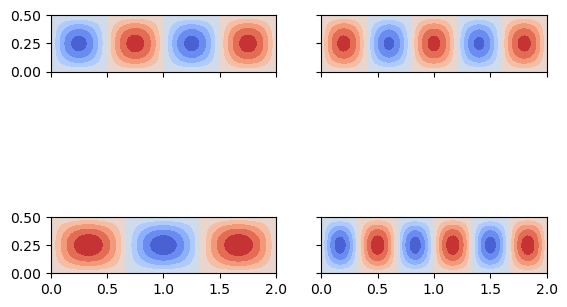

In [3]:
test_linear_buckling_plate(plot=True)

The same plate with `Quad4` elements and a constant membrane stress state
given directly with `update_KG_given_stress` (`tests/test_solver.py`):

## Given membrane stresses

`plate_matrices` builds the plate $a = 2$ m, $b = 0.5$ m, $h = 0.002$ m, $E =
203$ GPa, $\nu = 0.33$, with `Quad4` elements, and gives each element the
constant $N_{xx} = -1$ directly with `update_KG_given_stress`, without a static
solution. With this $b/h = 250$, the Mindlin plate buckles 0.01 % below the
Kirchhoff reference, so the reference is that of the element too. The test
compares the critical $N_{xx}$, as the stress
$\sigma_{cr} = -k_c \pi^2 E h^2/(12 (1 - \nu^2) b^2)$ times $h b$, with
Eq. (10.46) of Leissa (1969) (`rtol = 0.01`), the multiplier of
`linear_buckling` with the one of `scipy.sparse.linalg.eigsh` applied by hand
to the equilibrated matrices (`rtol = 1e-6`), and checks that the eigenvector
returned satisfies $(\boldsymbol{K}_{C0} + \lambda_1 \boldsymbol{K}_G)
\boldsymbol{u} = \boldsymbol{0}$ with a relative residual below $10^{-8}$, see
[Eigenvalue solvers and their verification](../eigenvalue_solvers.rst):

In [4]:
def plate_matrices(Nxx=-1., with_mass=False, nx=NX, ny=NY):
    r"""Assemble the simply supported plate and return ``KC0uu``, ``KGuu``,
    and optionally ``Muu``, with ``nx`` by ``ny`` nodes"""
    prop = isotropic_plate(E=E_PLATE, nu=NU_PLATE, thickness=H_PLATE,
                           rho=RHO_PLATE)
    data = Quad4Data()
    probe = Quad4Probe()
    xtmp = np.linspace(0, A_PLATE, nx)
    ytmp = np.linspace(0, B_PLATE, ny)
    xmesh, ymesh = np.meshgrid(xtmp, ytmp)
    ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten(),
                         np.zeros(nx*ny))).T
    x = ncoords[:, 0]
    y = ncoords[:, 1]
    ncoords_flatten = ncoords.flatten()
    nids = 1 + np.arange(ncoords.shape[0])
    nid_pos = dict(zip(nids, np.arange(len(nids))))
    nids_mesh = nids.reshape(nx, ny)
    n1s = nids_mesh[:-1, :-1].flatten()
    n2s = nids_mesh[1:, :-1].flatten()
    n3s = nids_mesh[1:, 1:].flatten()
    n4s = nids_mesh[:-1, 1:].flatten()
    num_elements = len(n1s)
    N = DOF*ncoords.shape[0]
    KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    KGr = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=INT)
    KGc = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=INT)
    KGv = np.zeros(data.KG_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    Mr = np.zeros(data.M_SPARSE_SIZE*num_elements, dtype=INT)
    Mc = np.zeros(data.M_SPARSE_SIZE*num_elements, dtype=INT)
    Mv = np.zeros(data.M_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    init_k_KC0 = 0
    init_k_KG = 0
    init_k_M = 0
    for n1, n2, n3, n4 in zip(n1s, n2s, n3s, n4s):
        quad = Quad4(probe)
        quad.n1, quad.n2, quad.n3, quad.n4 = n1, n2, n3, n4
        quad.c1 = DOF*nid_pos[n1]
        quad.c2 = DOF*nid_pos[n2]
        quad.c3 = DOF*nid_pos[n3]
        quad.c4 = DOF*nid_pos[n4]
        quad.init_k_KC0 = init_k_KC0
        quad.init_k_KG = init_k_KG
        quad.init_k_M = init_k_M
        quad.update_rotation_matrix(ncoords_flatten)
        quad.update_probe_xe(ncoords_flatten)
        quad.update_KC0(KC0r, KC0c, KC0v, prop)
        quad.update_KG_given_stress(Nxx, 0, 0, KGr, KGc, KGv)
        if with_mass:
            quad.update_M(Mr, Mc, Mv, prop)
        init_k_KC0 += data.KC0_SPARSE_SIZE
        init_k_KG += data.KG_SPARSE_SIZE
        init_k_M += data.M_SPARSE_SIZE
    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()
    KG = coo_matrix((KGv, (KGr, KGc)), shape=(N, N)).tocsc()
    bk = np.zeros(N, dtype=bool)
    edge = (np.isclose(x, 0.) | np.isclose(x, A_PLATE)
            | np.isclose(y, 0.) | np.isclose(y, B_PLATE))
    bk[0::DOF] = edge
    bk[1::DOF] = edge
    bk[2::DOF] = edge
    bu = ~bk
    out = [KC0[bu, :][:, bu], KG[bu, :][:, bu]]
    if with_mass:
        M = coo_matrix((Mv, (Mr, Mc)), shape=(N, N)).tocsc()
        out.append(M[bu, :][:, bu])
    return out

In [5]:
@pytest.mark.slow
def test_linear_buckling_plate():
    r"""End-to-end against the buckling load of Leissa (1969), Eq. (10.46),
    see the module documentation, and against the hand-rolled recipe used
    elsewhere in this suite

    With ``b/h = 250`` the Mindlin plate buckles 0.01 % below the reference.
    With the default Quad4, the MITC4 transverse shear and the slopes of
    `w` of KG at the two-by-two points, the buckling load is 0.44 % above
    it with 60x18 elements, 4.31 % with 20x6 elements, 1.03 % with 40x12
    elements and 0.23 % with 80x24 elements; with the slopes at the
    centroid, 0.69 %, 6.81 %, 1.61 % and 0.37 % with ``centroid_slopes =
    1``, and 0.41 %, 4.67 %, 1.09 % and 0.16 % with ``shear_model = 0``
    (measured on 2026-11-01).
    """
    Nxx = -1.
    KC0uu, KGuu = plate_matrices(Nxx=Nxx, nx=61, ny=19)
    eigvals, eigvecs = linear_buckling(KC0uu, KGuu, num_eigvalues=4)
    P_cr_calc = eigvals[0]*Nxx*B_PLATE

    kcmin = 1e6
    for m in range(1, 21):
        kc = (m*B_PLATE/A_PLATE + A_PLATE/(m*B_PLATE))**2
        kcmin = min(kc, kcmin)
    sigma_cr = -kcmin*np.pi**2*E_PLATE/(12*(1 - NU_PLATE**2))*(
        H_PLATE**2/B_PLATE**2)
    P_cr_theory = sigma_cr*H_PLATE*B_PLATE
    print('P_cr_calc %.4f  P_cr_theory %.4f' % (P_cr_calc, P_cr_theory))
    assert np.isclose(P_cr_theory, P_cr_calc, rtol=0.01)

    # NOTE the same answer as the recipe spelled out in the other tests of
    #      this suite. The two are not bit-identical because the shift
    #      differs, estimated here and hardcoded to 1 there, so they agree
    #      only to the tolerance requested of the eigensolver, which is
    #      1e-9 in both calls below
    lam_est, _ = linear_buckling(KC0uu, KGuu, num_eigvalues=4, tol=1e-9)
    P = diagonal_preconditioner(KC0uu)
    mu, _ = eigsh(A=P @ KGuu @ P, k=4, which='SM', M=P @ KC0uu @ P,
                  tol=1e-9, sigma=1., mode='cayley')
    lam = np.sort(-1./mu)
    lam = lam[lam > 0]
    print('linear_buckling %.9f  hand-rolled %.9f  rel diff %.2e'
          % (lam_est[0], lam[0], abs(lam_est[0]/lam[0] - 1)))
    assert np.isclose(lam_est[0], lam[0], rtol=1e-6)

    # NOTE the eigenvectors come back in the original scaling
    residual = np.linalg.norm(KC0uu @ eigvecs[:, 0]
                              + eigvals[0]*(KGuu @ eigvecs[:, 0]))
    residual /= np.linalg.norm(KC0uu @ eigvecs[:, 0])
    print('eigenvector residual %.3e' % residual)
    assert residual < 1e-8

In [6]:
test_linear_buckling_plate()

P_cr_calc -12043.7552  P_cr_theory -11991.3497


linear_buckling 24087.510384995  hand-rolled 24087.509157310  rel diff 5.10e-08
eigenvector residual 7.269e-10


With 60 x 18 elements the critical load is 0.44 % above the reference.

## References

- Belytschko, T. and Leviathan, I., Physical stabilization of the 4-node
  shell element with one point quadrature, Computer Methods in Applied
  Mechanics and Engineering, 113(3-4), 321-350, 1994.
  https://doi.org/10.1016/0045-7825(94)90052-3
- Leissa, A. W., Vibration of Plates, NASA SP-160, 1969.